# OpenDrift GBR Simulation using LarvaeDriftV4 & PostProcessingV2
1. **Sets up the spawning event.** Spawning nights are defined in local time (AEST),
   and particles are released at random times within each night.
2. **Seeds larvae on source reefs.** Reefs within a chosen study area are selected
   from the Seamap Australia GBR reef layer. Particles are allocated in proportion
   to reef area (with a minimum per reef) and placed at random positions inside each
   reef polygon.
3. **Runs the dispersal model.** Larvae are tracked with OpenDrift, using a custom
   model (`CoralLarvae`) driven by ROMS ocean currents and GFS winds. Larvae are held
   at the surface for their first hours, then mix vertically with wind-driven
   turbulence and sink slowly. Particles that hit the coastline strand, and those
   leaving the model domain are removed.
4. **Checks the run.** It reports particle fates and sanity checks, and plots
   particle paths and vertical positions.
5. **Applies settlement and mortality.** Post-processing treats each particle as a
   bundle of larvae that gradually settles onto reefs once competent, with
   background mortality applied by age. The result is a reef-to-reef connectivity
   matrix, settlement and self-recruitment statistics, and per-reef metrics.

Settlement and mortality are deliberately kept out of the model run. The run only
moves particles, so biological assumptions can be changed and re-applied in seconds
without re-running the model.

In [1]:
# =============================================================================
# Setup and imports
# =============================================================================
# This notebook assumes the repository layout:
#
#   <repo>/
#   ├── notebooks/        <- this notebook
#   └── models/
#       └── LarvaeDriftV4.py   (custom OpenDrift model: CoralLarvae)
#
# Recommended environment: install OpenDrift via conda-forge
# (see https://opendrift.github.io/install.html), which brings in
# compatible versions of PROJ, cartopy, geopandas and netCDF4.
# =============================================================================

import os
import sys
from pathlib import Path

# --- Optional: PROJ data path -------------------------------------------------
# Cartopy and geopandas rely on PROJ. In a standard conda environment this is
# found automatically and you can leave this block alone.
# If you see errors like "proj.db not found" or "PROJ: cannot find data",
# uncomment the lines below. They point PROJ at the data folder inside your
# active conda environment. This must run BEFORE cartopy/geopandas/pyproj
# are imported.
#
# proj_dir = Path(sys.prefix) / "share" / "proj"
# os.environ["PROJ_DATA"] = str(proj_dir)   # PROJ >= 9.1
# os.environ["PROJ_LIB"] = str(proj_dir)    # older PROJ versions

# --- Locate the custom larval model --------------------------------------------
# Expected layout:
#   Thesis/
#   ├── Model_Simulation_Config.ipynb   <- this notebook (run from here)
#   ├── models/
#   │   └── LarvaeDriftV4.py            (custom OpenDrift model: CoralLarvae)
#   └── Data/
#       └── SHP/                        (reef, release-area, coastline, domain shapefiles)
REPO_DIR = Path.cwd()
MODELS_DIR = REPO_DIR / "models"
if not (MODELS_DIR / "LarvaeDriftV4.py").exists():
    raise FileNotFoundError(
        f"Could not find LarvaeDriftV4.py in {MODELS_DIR}. "
        "Run this notebook from the repository's top-level folder."
    )
sys.path.insert(0, str(MODELS_DIR))

# --- General -------------------------------------------------------------------
import datetime
import pickle
import random
import re
import time

import numpy as np
import pandas as pd
import xarray as xr
from netCDF4 import Dataset
from scipy.spatial import cKDTree
from geopy.distance import geodesic

# --- Plotting and spatial --------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import geopandas as gpd
from shapely.geometry import Point, Polygon
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- OpenDrift -------------------------------------------------------------------
# Readers for ROMS output (native and CF-compliant NetCDF) and coastline shapefiles
from opendrift.readers import reader_ROMS_native
from opendrift.readers import reader_netCDF_CF_generic
from opendrift.readers import reader_shape
from opendrift.models.oceandrift import OceanDrift

# Custom coral larvae model (extends OpenDrift; see models/LarvaeDriftV4.py)
from LarvaeDriftV4 import CoralLarvae

/srv/tljh/user/envs/opendrift/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Model Configuration
Set file paths and config settings here, then run the rest of the notebook

In [23]:
# =============================================================================
# CONFIGURATION: edit this cell only
# =============================================================================
# --- Paths (edit to match your machine) ---
DATA_DIR   = REPO_DIR / "Data"
SHP_DIR    = DATA_DIR / "SHP"
OUTPUT_DIR = REPO_DIR / "outputs"

# ROMS and GFS forcing are large and NOT included in the repository.
# Point these at wherever you have stored them.
FORCING_DIR  = Path("/srv/data/GBR")
ROMS_PATTERN = FORCING_DIR / "gbr_his_{date}.nc"     # one file per day, date = YYYYMMDD
GFS_FILE     = FORCING_DIR / "GFS_AUS_20251xxx.nc"
GFS_NAME_MAPPING = {...}        # CHECK: copy standard_name_mapping from your GFS reader cell

REEF_SHP     = SHP_DIR / "SeamapAus_GBR_Reefs.shp"   # CHECK: real file names
RELEASE_SHP  = SHP_DIR / "release_reefs.shp"
BOUNDARY_SHP = SHP_DIR / "ROMS_domain_extent.shp"
COAST_SHP    = FORCING_DIR / "GBR_polygons.shp"

# --- Spawning (local AEST, UTC+10, no daylight saving in QLD) ---
SPAWN_NIGHTS_LOCAL = [
    (datetime.datetime(2025, 11, 9, 20, 30),  datetime.datetime(2025, 11, 10, 4, 0)),
    (datetime.datetime(2025, 11, 10, 20, 30), datetime.datetime(2025, 11, 11, 4, 0)),
]
AGE_MAX = datetime.timedelta(hours=506.5)   # common age cap so Nov and Dec runs are comparable

# --- Seeding ---
STUDY_AREA_ID   = 4       # polygon id in RELEASE_SHP
TOTAL_PARTICLES = 47
MIN_PER_REEF    = 1

# --- Physics / behaviour ---
MLD_FALLBACK_M     = 10       # no MLD in ROMS output, so a constant is used
SURFACE_HOURS      = 8
TERMINAL_VELOCITY  = -2.5e-5  # m/s, slow sinking after the surface phase
BACKGROUND_DIFFUSIVITY = 1e-4   # m2/s, floor for vertical diffusivity
MAX_SPEED = 3                   # m/s, used by OpenDrift to size reader buffers
CURRENT_UNCERTAINTY = 0.01
WIND_UNCERTAINTY    = 0.5

# --- Reproducibility ---
POSITION_SEED, RELEASE_SEED, RUN_SEED = 42, 42, 1

# --- Output ---
RUN_NAME = f"NovRun_MLD{MLD_FALLBACK_M}"

## Spawning times and run duration
Spawning windows are defined in local time (AEST) in the config cell and converted to UTC here, because the ROMS and GFS forcing are in UTC. The run starts at the first release and continues until the last-released larvae reach AGE_MAX.

In [24]:
AEST = datetime.timedelta(hours=10)    # Queensland: UTC+10, no daylight saving

# Convert spawning windows from local time to UTC
nights = [(start - AEST, end - AEST) for start, end in SPAWN_NIGHTS_LOCAL]

t0 = nights[0][0]                                 # first possible release (UTC)
duration = (nights[-1][1] - t0) + AGE_MAX         # last release + age cap
run_end = t0 + duration

# ROMS days to load: every calendar day the run touches, plus one spare day
# so the reader can interpolate up to the final time step
ndays = (run_end.date() - t0.date()).days + 2
model_days = [t0 + datetime.timedelta(days=d) for d in range(ndays)]

print('Spawning nights (UTC):')
for start, end in nights:
    print(f'  {start} -> {end}')
print(f't0: {t0} | duration: {duration} | run end: {run_end}')
print(f'ROMS days to load: {ndays}')

Spawning nights (UTC):
  2025-11-09 10:30:00 -> 2025-11-09 18:00:00
  2025-11-10 10:30:00 -> 2025-11-10 18:00:00
t0: 2025-11-09 10:30:00 | duration: 22 days, 10:00:00 | run end: 2025-12-01 20:30:00
ROMS days to load: 24


## Load forcing data
Ocean currents, temperature and bathymetry come from daily ROMS history files. Winds come from GFS, already converted to OpenDrift’s CF format.

In [25]:
# One ROMS history file per day, named gbr_his_YYYYMMDD.nc
roms_files = [str(ROMS_PATTERN).format(date=d.strftime('%Y%m%d')) for d in model_days]

missing = [f for f in roms_files if not Path(f).exists()]
if missing:
    raise FileNotFoundError(
        f'{len(missing)} ROMS file(s) not found, e.g. {missing[0]}. '
        'Check ROMS_PATTERN in the config cell.'
    )

# Wind forcing
gfs = reader_netCDF_CF_generic.Reader(str(GFS_FILE), standard_name_mapping=GFS_NAME_MAPPING)

# Ocean forcing.
# Two warnings are expected here and are harmless:
#   "Duplicate variables for land_binary_mask"  (OpenDrift picks mask_psi)
#   "No proj string ... using 'fakeproj'"       (normal for native ROMS grids)
roms = reader_ROMS_native.Reader(roms_files)

## Select source reefs
All GBR reef polygons are loaded, then only those falling entirely within the chosen study area (STUDY_AREA_ID) are kept as spawning sources.

In [26]:
# All GBR reef polygons (Seamap Australia)
gbr = gpd.read_file(REEF_SHP)

# Many reefs are named just 'U/N Reef'. Give each a unique name using its GBR_ID
# so reefs can be told apart in the connectivity results.
unnamed = gbr['GBR_NAME'].str.strip().str.upper().isin(['U/N REEF', 'U/N'])   # CHECK: list was cut off
gbr.loc[unnamed, 'GBR_NAME'] = 'U/N ' + gbr.loc[unnamed, 'GBR_ID'].astype(str)

# Study area polygons; several sizes are stored in one file, keyed by 'id'
seeding_area = gpd.read_file(RELEASE_SHP)
seeding_area = seeding_area[seeding_area['id'] == STUDY_AREA_ID]

# Same CRS before any spatial operation
gbr = gbr.to_crs(seeding_area.crs)

# Keep reefs lying fully inside the study area
seed_reefs = gpd.sjoin(gbr, seeding_area, predicate='within', how='inner')   # CHECK: line was cut off
print(f'{len(seed_reefs)} reef polygons selected as spawning sources')

46 reef polygons selected as spawning sources


## Coastline and land mask
A local high-resolution coastline is used instead of OpenDrift’s global default, which is too coarse for reef-scale stranding.

In [27]:
reader_landmask_local = reader_shape.Reader.from_shpfiles(str(COAST_SHP))
land_gdf = gpd.read_file(COAST_SHP).to_crs(gbr.crs)   # for plotting only

## Allocate particles to reef
Each reef with a positive area gets MIN_PER_REEF particles. The rest are shared in proportion to reef area, using the largest-remainder method so the total is exactly TOTAL_PARTICLES.

In [28]:
seed_reefs = seed_reefs.copy()
seed_reefs['area_ha'] = seed_reefs['Area_HA'].fillna(0)
area = seed_reefs['area_ha'].to_numpy(float)
eligible = area > 0                                # cays / zero-area polygons are not seeded

# 1. Set aside the guaranteed minimum; 2. share the rest by area
to_share = TOTAL_PARTICLES - MIN_PER_REEF * eligible.sum()
assert to_share >= 0, 'More eligible reefs than particles: lower MIN_PER_REEF or raise TOTAL_PARTICLES'

raw = np.zeros(len(area))
raw[eligible] = area[eligible] / area[eligible].sum() * to_share

# Largest remainder: round down, then give the leftover particles to the
# reefs with the biggest fractional parts
n = np.floor(raw).astype(int)
remainder = int(to_share - n.sum())
n[np.argsort(-(raw - n), kind='stable')[:remainder]] += 1
n[eligible] += MIN_PER_REEF

seed_reefs['n_particles'] = n

print('Total particles:', seed_reefs['n_particles'].sum())
print(f'Reef polygons: {len(seed_reefs)} | seeded: {(n > 0).sum()} | '
      f'zero-area (not seeded): {(~eligible).sum()}')

Total particles: 47
Reef polygons: 46 | seeded: 46 | zero-area (not seeded): 0


## Seed positions within each reef
Particles are placed uniformly at random inside each reef polygon by rejection sampling: draw points in the polygon’s bounding box and keep those that fall inside.

In [29]:
random.seed(POSITION_SEED)    # same positions on every run

def random_points_in_polygon(number, polygon):
    """Return `number` random shapely Points inside `polygon` (rejection sampling)."""
    points = []
    min_x, min_y, max_x, max_y = polygon.bounds
    while len(points) < number:
        point = Point(random.uniform(min_x, max_x), random.uniform(min_y, max_y))
        if polygon.contains(point):
            points.append(point)
    return points

seed_points = []
seed_reef_names = []          # source reef of each particle

for _, row in seed_reefs.iterrows():
    reef_points = random_points_in_polygon(row['n_particles'], row['geometry'])
    seed_points.extend(reef_points)
    seed_reef_names.extend([row['GBR_NAME']] * row['n_particles'])

seed_lon = np.array([p.x for p in seed_points])
seed_lat = np.array([p.y for p in seed_points])

# OpenDrift's origin_marker must be an integer, so map each reef name to an
# integer ID. The lookup is saved with the output for post-processing.
name_to_marker = {name: i for i, name in enumerate(seed_reefs['GBR_NAME'])}
marker_to_name = {i: name for name, i in name_to_marker.items()}
seed_marker = np.array([name_to_marker[name] for name in seed_reef_names])

assert len(seed_lon) == len(seed_lat) == len(seed_marker) == TOTAL_PARTICLES
print('Seed positions generated:', len(seed_lon))

Seed positions generated: 47


## Model Configuration
CoralLarvae extends OpenDrift’s OceanDrift with coral-specific vertical behaviour (see models/LarvaeDriftV4.py).

In [30]:
o = CoralLarvae(loglevel=40)    # 40 = errors only; use 20 for progress, 0 for full debug output

# Reader order matters: the coastline goes first so it is used as the land mask
o.add_reader([reader_landmask_local, roms, gfs])

# --- Advection and mixing ---
o.set_config('drift:advection_scheme', 'runge-kutta4')
o.set_config('drift:vertical_mixing', True)
o.set_config('vertical_mixing:diffusivitymodel', 'windspeed_Large1994')
o.set_config('drift:vertical_mixing_at_surface', True)
o.set_config('vertical_mixing:background_diffusivity', BACKGROUND_DIFFUSIVITY)
o.set_config('drift:stokes_drift', False)    # no wave model available

# ROMS output has no mixed-layer depth, so a constant fallback is used
o.set_config('environment:fallback:ocean_mixed_layer_thickness', MLD_FALLBACK_M)

# --- Random perturbations (stochastic spread of trajectories) ---
o.set_config('drift:current_uncertainty', CURRENT_UNCERTAINTY)
o.set_config('drift:wind_uncertainty', WIND_UNCERTAINTY)
o.max_speed = MAX_SPEED

# --- Boundaries ---
o.set_config('general:use_auto_landmask', False)      # use the local coastline instead
o.set_config('general:coastline_action', 'stranding') # particles hitting land are deactivated
o.set_config('general:seafloor_action', 'lift_to_seafloor')
o.set_domain_boundary(gpd.read_file(BOUNDARY_SHP))    # particles leaving the ROMS domain are deactivated
o.set_config('seed:ocean_only', True)

# --- Vertical behaviour: held at the surface, then passive ---
o.set_config('vertical_behaviour:surface_period_hours', SURFACE_HOURS)
o.set_config('vertical_behaviour:buoyant_speed', 0)    # m/s upward
o.set_config('vertical_behaviour:sink_speed', 0)       # m/s downward

# --- Biology ---
# Not used to stop the run (AGE_MAX sets the duration), but stored in the
# output metadata for completeness
o.set_config('pelagic_larval_duration', 28.0)
o.set_config('biology:background_mortality_rate', 0)   # day^-1; mortality is applied in post-processing

## Release times
Particles are split evenly across the spawning nights. Each particle gets a random release time within its night. The earliest particle on the first night is fixed to the window start so the first release equals t0, which OpenDrift requires.

In [31]:
assert o.num_elements_scheduled() == 0, 'Already seeded: re-run the model configuration cell first'

rng = np.random.default_rng(RELEASE_SEED)

n_total = len(seed_lon)
night_idx = np.arange(n_total) % len(nights)    # alternate particles between nights
u = rng.uniform(0, 1, n_total)                  # position within the night's window (0-1)

# Pin the earliest first-night particle to the window start
first_night = np.where(night_idx == 0)[0]
u[first_night[np.argmin(u[first_night])]] = 0.0

starts = np.array([nights[k][0] for k in night_idx], dtype='datetime64[s]')
window_s = np.array([(nights[k][1] - nights[k][0]).total_seconds() for k in night_idx])
release_times = list((starts + (u * window_s).astype('timedelta64[s]')).astype(datetime.datetime))   # CHECK: line was cut off

o.seed_elements(seed_lon, seed_lat, time=release_times,
                terminal_velocity=TERMINAL_VELOCITY, origin_marker=seed_marker)

# --- Checks ---
assert min(release_times) == t0, 'First release must equal t0'
rel = pd.to_datetime(pd.Series(release_times))
print('Particles per night:', np.bincount(night_idx))
print('Release window:', rel.min(), '->', rel.max())

Particles per night: [24 23]
Release window: 2025-11-09 10:30:00 -> 2025-11-10 17:49:01


## Run the model
Output is written hourly to OUTPUT_DIR/RUN_NAME/. The reef ID lookup and seeding table are saved alongside so results can be analysed without re-running. Expect around 30 minutes for 40,000 particles.

In [32]:
run_dir = OUTPUT_DIR / RUN_NAME
run_dir.mkdir(parents=True, exist_ok=True)
outfile = run_dir / f'{RUN_NAME}.nc'

# OpenDrift can't overwrite an existing file, so any previous output for this run is deleted
if outfile.exists():
    outfile.unlink()

# Save the reef lookup and particle allocation for post-processing
seed_reefs[['GBR_ID', 'GBR_NAME', 'area_ha', 'n_particles']].assign(
    origin_marker=seed_reefs['GBR_NAME'].map(name_to_marker)
).to_csv(run_dir / f'{RUN_NAME}_reefs.csv', index=False)

# Forcing must cover the whole run
print('ROMS:', roms.start_time, '->', roms.end_time)
print('GFS: ', gfs.start_time, '->', gfs.end_time)
print('Run ends:', run_end)
assert run_end <= roms.end_time, 'ROMS files do not cover the run'
assert run_end <= gfs.end_time, 'GFS wind does not cover the run'

np.random.seed(RUN_SEED)    # makes the stochastic drift reproducible

run_start = time.time()
o.run(duration=duration, time_step=900, time_step_output=900,
      export_variables=['status', 'age_seconds', 'z', 'origin_marker',
                        'sea_floor_depth_below_sea_level'],
      outfile=str(outfile))
run_elapsed = time.time() - run_start
print(f'Run finished in {run_elapsed / 60:.1f} min')

ROMS: 2025-11-09 00:00:00 -> 2025-12-02 23:00:00
GFS:  2025-10-01 00:00:00 -> 2025-12-31 21:00:00
Run ends: 2025-12-01 20:30:00
Run finished in 4.7 min


## Load basic results
Load the run output. Arrays have shape (trajectory, time); positions are NaN before a particle is released and after it is deactivated.

In [33]:
ds = xr.open_dataset(outfile)

traj_lon = ds['lon'].values
traj_lat = ds['lat'].values
traj_z   = ds['z'].values
age_days = ds['age_seconds'].values / 86400.0
status   = ds['status'].values

n_particles = traj_lon.shape[0]

# Index of each particle's last recorded position (its final position or deactivation point)
valid = np.isfinite(traj_lon)
last = valid.shape[1] - 1 - np.argmax(valid[:, ::-1], axis=1)
rows = np.arange(n_particles)

seed_lon_out, seed_lat_out = traj_lon[rows, np.argmax(valid, axis=1)], traj_lat[rows, np.argmax(valid, axis=1)]
end_lon, end_lat = traj_lon[rows, last], traj_lat[rows, last]
end_age = age_days[rows, last]
end_status = status[rows, last]

## Model performance
How each particle’s run ended, how long particles stayed in the water, and basic checks for numerical problems.

In [34]:
# Map status codes to names (stored in the output file's metadata)
codes = np.atleast_1d(ds['status'].attrs['flag_values'])
names = ds['status'].attrs['flag_meanings'].split()
code_to_name = dict(zip(codes.astype(int), names))

print(f'Particles: {n_particles}')

print('\n--- Particle fates at end of run ---')
for code, count in zip(*np.unique(end_status.astype(int), return_counts=True)):
    print(f'  {code_to_name.get(code, code)}: {count} ({100 * count / n_particles:.1f}%)')

print('\n--- Time in the water (days) ---')
print(f'  min {end_age.min():.2f} | mean {end_age.mean():.2f} | max {end_age.max():.2f}')

print('\n--- Sanity checks ---')
print(f'  Infinite positions: {np.isinf(traj_lon).sum() + np.isinf(traj_lat).sum() + np.isinf(traj_z).sum()}')
print(f'  Positions above the surface (z > 0.01 m): {np.nansum(traj_z > 0.01)}')
print(f'  Deepest position: {np.nanmin(traj_z):.1f} m')
print(f'  Lon range: {np.nanmin(traj_lon):.3f} to {np.nanmax(traj_lon):.3f}')
print(f'  Lat range: {np.nanmin(traj_lat):.3f} to {np.nanmax(traj_lat):.3f}')

Particles: 47

--- Particle fates at end of run ---
  active: 26 (55.3%)
  stranded: 9 (19.1%)
  left_domain: 12 (25.5%)

--- Time in the water (days) ---
  min 0.01 | mean 17.25 | max 22.38

--- Sanity checks ---
  Infinite positions: 0
  Positions above the surface (z > 0.01 m): 0
  Deepest position: -75.7 m
  Lon range: 145.936 to 148.817
  Lat range: -19.541 to -16.492


## Particle positions
Where particles were released (orange) and where they were at the end of the run or when deactivated (black).

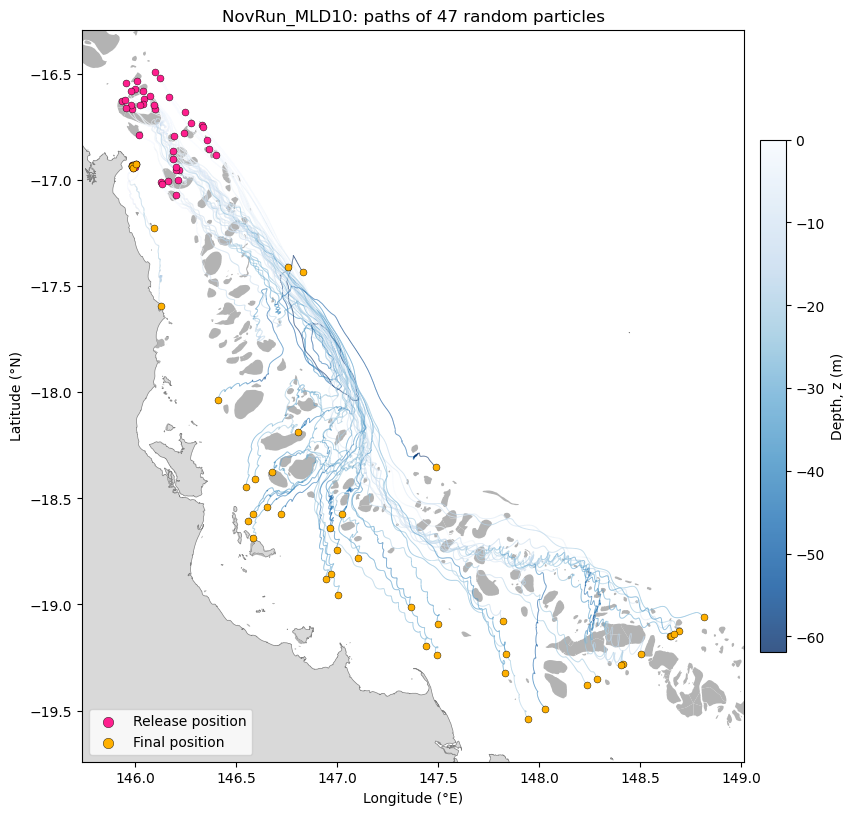

In [38]:
from matplotlib.collections import LineCollection

N_PATHS = 1000          # particles to draw (paths, start and end points)
START_COLOUR = '#FF1F8E'  # hot pink
END_COLOUR   = '#FFB000'  # amber

rng = np.random.default_rng(0)
sample = np.sort(rng.choice(n_particles, size=min(N_PATHS, n_particles), replace=False))

# Build line segments between consecutive hourly positions, coloured by mean depth
x, y, zz = traj_lon[sample], traj_lat[sample], traj_z[sample]
ok = np.isfinite(x[:, :-1]) & np.isfinite(x[:, 1:])
segs = np.stack([np.column_stack([x[:, :-1][ok], y[:, :-1][ok]]),
                 np.column_stack([x[:, 1:][ok],  y[:, 1:][ok]])], axis=1)
seg_z = 0.5 * (zz[:, :-1][ok] + zz[:, 1:][ok])

fig, ax = plt.subplots(figsize=(9, 9))

land_gdf.plot(ax=ax, color='0.85', edgecolor='0.5', linewidth=0.5, zorder=1)
gbr.plot(ax=ax, color='0.7', linewidth=0, zorder=1)

lc = LineCollection(segs, cmap='Blues_r', linewidths=0.6, alpha=0.8, zorder=2)
lc.set_array(seg_z)
lc.set_clim(np.nanpercentile(seg_z, 1), 0)   # stretch colours over the typical depth range
ax.add_collection(lc)

ax.scatter(seed_lon_out[sample], seed_lat_out[sample], s=25, color=START_COLOUR,
           edgecolor='k', linewidth=0.3, zorder=3, label='Release position')
ax.scatter(end_lon[sample], end_lat[sample], s=25, color=END_COLOUR,
           edgecolor='k', linewidth=0.3, zorder=4, label='Final position')

pad = 0.2
ax.set_xlim(np.nanmin(traj_lon) - pad, np.nanmax(traj_lon) + pad)
ax.set_ylim(np.nanmin(traj_lat) - pad, np.nanmax(traj_lat) + pad)
ax.set_aspect(1 / np.cos(np.deg2rad(np.nanmean(traj_lat))))   # correct lon/lat proportions
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')
ax.set_title(f'{RUN_NAME}: paths of {len(sample):,} random particles')
ax.legend(loc='lower left', markerscale=1.5)

cb = fig.colorbar(lc, ax=ax, shrink=0.6, pad=0.02)
cb.set_label('Depth, z (m)')

plt.tight_layout()
plt.savefig(run_dir / f'{RUN_NAME}_positions.png', dpi=200)
plt.show()

## Vertical positions
Raw depth paths for a random sample of particles. The dashed line marks the fallback mixed-layer depth.

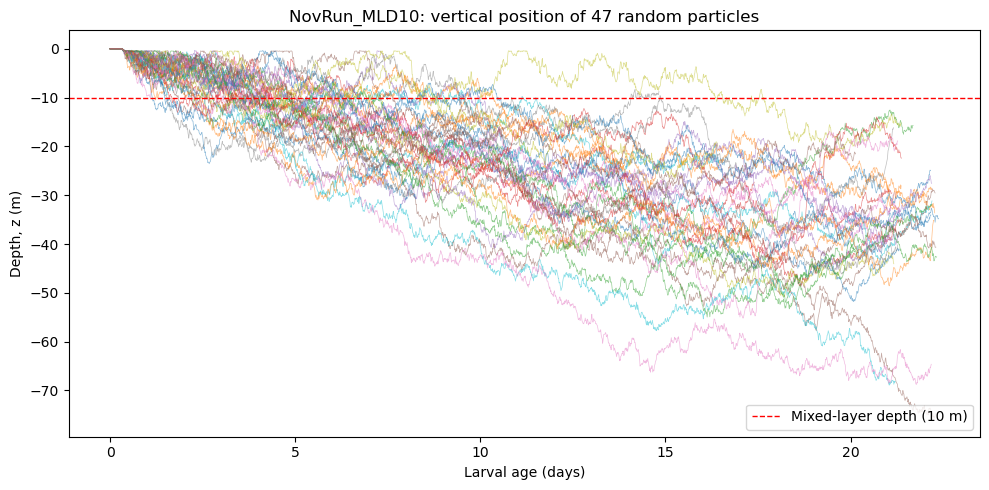

In [37]:
N_SHOW = 47    # number of particles to plot; all 40,000 is slow and unreadable

rng = np.random.default_rng(0)
sample = rng.choice(n_particles, size=min(N_SHOW, n_particles), replace=False)

fig, ax = plt.subplots(figsize=(10, 5))
for i in sample:
    ok = np.isfinite(traj_z[i])
    ax.plot(age_days[i, ok], traj_z[i, ok], linewidth=0.5, alpha=0.5)

ax.axhline(-MLD_FALLBACK_M, color='red', linestyle='--', linewidth=1,
           label=f'Mixed-layer depth ({MLD_FALLBACK_M} m)')
ax.set_xlabel('Larval age (days)')
ax.set_ylabel('Depth, z (m)')
ax.set_title(f'{RUN_NAME}: vertical position of {len(sample)} random particles')
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(run_dir / f'{RUN_NAME}_depth.png', dpi=200)
plt.show()

## Post-processing: settlement, mortality and connectivity

OpenDrift only moves particles. Settlement and mortality are applied afterwards by models/PostProcessingV2.py, working on the saved output file. This keeps the expensive model run separate from the biological assumptions: settlement rules, competency window and mortality can be changed and re-applied in seconds without re-running the model.

Each particle is treated as a bundle of larvae. Once competent, a bundle loses a fraction of its larvae to settlement every hour it spends over a reef, and the remainder keeps drifting and can settle on later reefs. Mortality is applied as exponential decay with age, which is why the model run uses background_mortality_rate = 0.

seed_reefs must be in the same order as when the particles were seeded, since origin_marker indexes into it. Using the seed_reefs built earlier in this notebook guarantees this.

In [39]:
import PostProcessingV2 as pp

# Basic run information read from the output file
info = pp.run_info(ds, label=RUN_NAME)
print(f"{info['n_particles']} particles | release {info['first_release']} -> {info['last_release']} "
      f"| run end {info['end']}")

# Age cap: the oldest age that EVERY particle reaches, so early and late releases
# are treated equally. With several runs, pass them all to get one shared cap.
AGE_CAP = pp.common_age_cap(ds)
print(f'Age cap: {AGE_CAP} h ({AGE_CAP / 24:.2f} days)')

# Reefs larvae can settle on: all GBR reefs, excluding the mainland and zero-area cays
dest_reefs = pp.destination_reefs(gbr)
print(f'{len(dest_reefs)} destination reefs')

47 particles | release 2025-11-09 10:30:00 -> 2025-11-10 17:45:00 | run end 2025-12-01 20:30:00
Age cap: 506.5 h (21.10 days)
3862 destination reefs


## Apply settlement and mortality

These are the settings used in the report. settle() returns a results dictionary that every other post-processing function takes as input.

In [41]:
SETTINGS = dict(
    method='bundle',                  # 'bundle', 'per_visit' or 'first_contact' (see PostProcessingV2.py)
    competency_start_days=4,          # larvae cannot settle before this age
    competency_end_days=28,
    depth_min=-np.inf, depth_max=0,   # depth band where settlement is allowed (no limit)
    settle_fraction_per_hour=0.3,     # 30% of the remaining bundle settles per hour over a reef
    mortality_per_day=0.05,           # background mortality, exp(-0.05 * age in days)
    age_max_h=AGE_CAP,
)

res = pp.settle(ds, dest_reefs, seed_reefs, label=RUN_NAME, **SETTINGS)

pp.summary(res)

[NovRun_MLD10] Applying mortality exp(-0.05 * age) in post-processing.


run                                 NovRun_MLD10
method                                    bundle
age cap (days)                         21.104167
mortality applied (/day)                    0.05
larvae released (particles)                   47
settled (%)                            58.210318
mortality (%)                          25.261588
Stranded (%)                           14.706319
Left domain (%)                         0.133613
still drifting at age cap (%)           1.688162
settled on seeding reefs (%)           14.129774
self-recruitment (% released)                0.0
self-recruitment (% of settlers)             0.0
sink reefs reached                           109
mean settlement age (days)              5.867357
median settlement age (days)            4.895833
Name: NovRun_MLD10, dtype: object

## Figures
Connectivity matrix: % of each source reef’s released larvae settling on each sink reef (30 most-supplied sinks shown).
Fates over age: how released larvae are split between settled, lost and still drifting as they age.
Settlement age: when settlement happens.
Mortality check: confirms mortality was applied as intended (the model curve should sit on the dashed line).

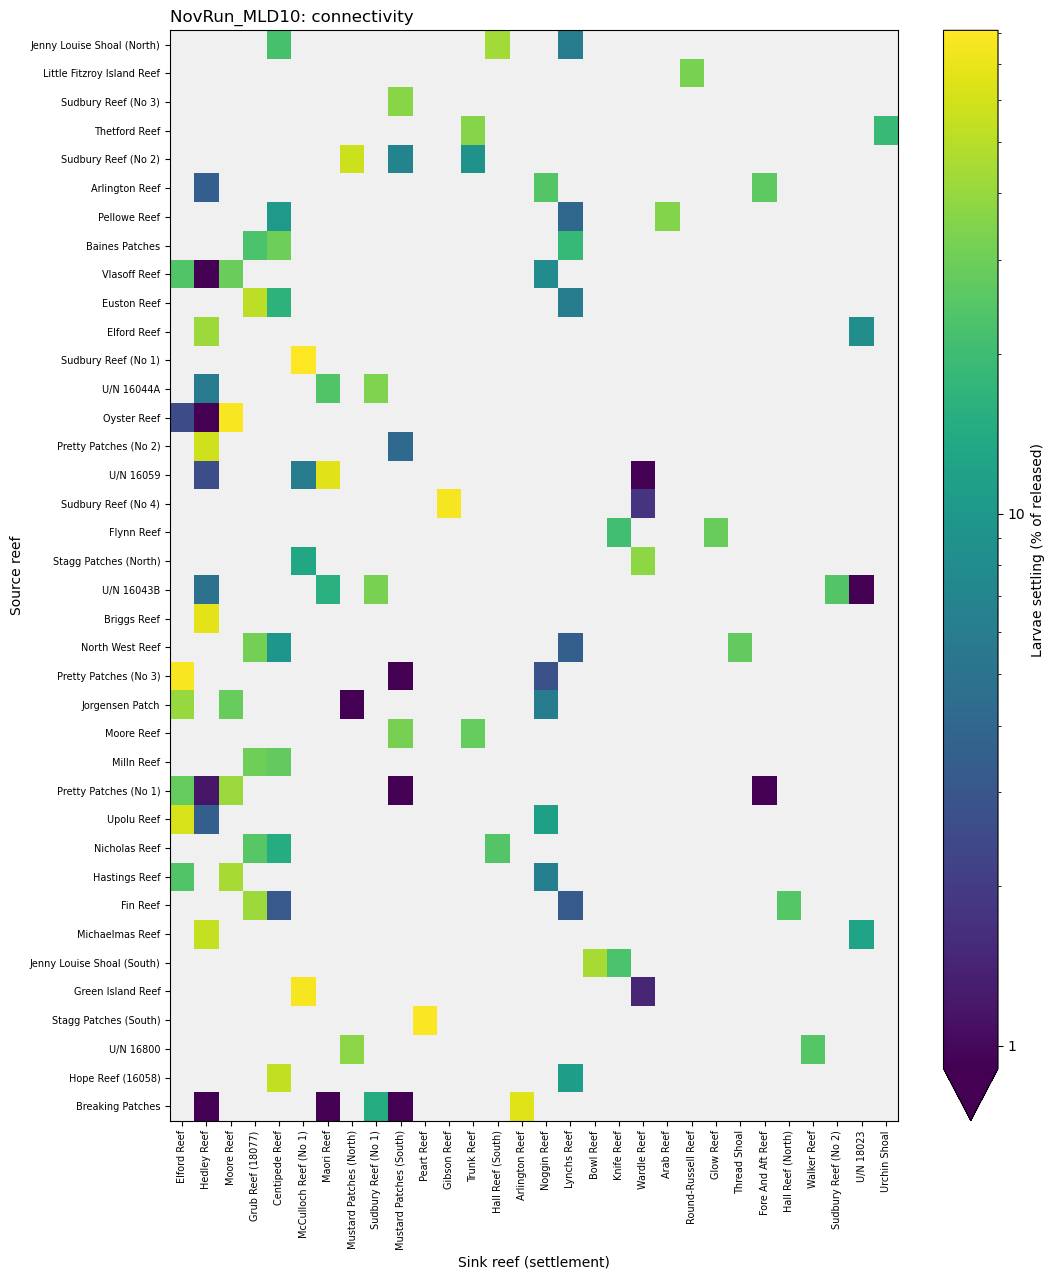

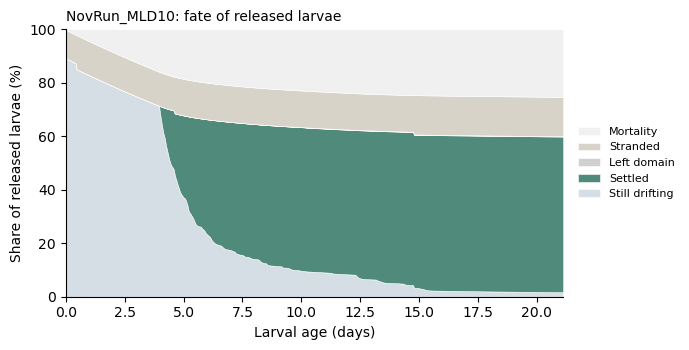

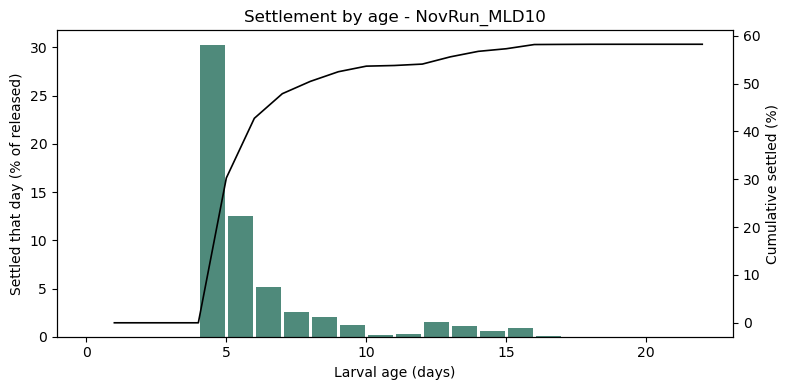

In [43]:
matrix, counts = pp.connectivity_matrix(res, normalise='released')
fig, ax = pp.plot_connectivity_matrix(matrix, top_n=30, title=f'{RUN_NAME}: connectivity')
plt.show()

fig, ax = pp.plot_fates_over_age(res, title=f'{RUN_NAME}: fate of released larvae')
plt.show()

fig, ax = pp.plot_settlement_age(res)
plt.show()

## Per-reef tables and saving outputs

source_table() summarises each source reef; reef_metrics() gives source/sink metrics for every reef involved. save_outputs() writes the summary, connectivity matrices, fates and per-particle settlement to CSV.

In [44]:
display(pp.source_table(res).head(10))

display(pp.reef_metrics(res).sort_values('recv_share', ascending=False).head(10))

pp.save_outputs(res, run_dir / 'postprocessing', prefix=f'{RUN_NAME}_')

# If you want GIS layers for QGIS, pp.export_reef_metrics() and pp.export_links() write .gpkg files from the same res.

,released,settled (%),self-recruitment (%),sinks reached
Arlington Reef,2,60.753752,0.0,4
Jenny Louise Shoal (North),1,72.864317,0.0,12
Sudbury Reef (No 3),1,36.526094,0.0,1
Thetford Reef,1,54.833052,0.0,3
U/N 16054C,1,0.000000,0.0,0
Little Fitzroy Island Reef,1,32.875303,0.0,1
Sudbury Reef (No 2),1,73.509786,0.0,4
U/N 16054D,1,0.000000,0.0,0
Pellowe Reef,1,72.741062,0.0,11
Scott Reef,1,0.000000,0.0,0


,released,src_pct,self_pct,export,received,import,recv_share,n_sinks,n_srcs,ss_index
reef,,,,,,,,,,
Elford Reef,1.0,68.223074,0.0,0.682231,2.577722,2.577722,9.421894,6,7,-0.581447
Hedley Reef,NaN,NaN,NaN,0.000000,2.482154,2.482154,9.072581,0,13,-1.000000
Moore Reef,1.0,60.375489,0.0,0.603755,2.221790,2.221790,8.120920,2,5,-0.572645
Grub Reef (18077),NaN,NaN,NaN,0.000000,2.036814,2.036814,7.444808,0,6,-1.000000
Centipede Reef,NaN,NaN,NaN,0.000000,1.878220,1.878220,6.865128,0,9,-1.000000
McCulloch Reef (No 1),NaN,NaN,NaN,0.000000,1.770353,1.770353,6.470860,0,4,-1.000000
Maori Reef,NaN,NaN,NaN,0.000000,1.057105,1.057105,3.863852,0,4,-1.000000
Mustard Patches (North),NaN,NaN,NaN,0.000000,0.946034,0.946034,3.457872,0,3,-1.000000
Noggin Reef,NaN,NaN,NaN,0.000000,0.836654,0.836654,3.058073,0,6,-1.000000


Saved outputs to /home/jupyter-haylee/Thesis/outputs/NovRun_MLD10/postprocessing


## Comparing runs

This notebook produces one run. To compare runs (e.g. November vs December spawning, or a sensitivity test against its baseline), run this notebook once per scenario, then load the output files together. Two points matter:

Use one shared age cap so every run is assessed over the same larval ages: pp.common_age_cap(ds_a, ds_b).
Use identical settlement settings for every run, changing only age_max_h to the shared cap.

In [ ]:
ds_nov = xr.open_dataset('outputs/NovRun_MLD20/NovRun_MLD20.nc')
ds_dec = xr.open_dataset('outputs/DecRun_MLD20/DecRun_MLD20.nc')

SETTINGS['age_max_h'] = pp.common_age_cap(ds_nov, ds_dec)
res_nov = pp.settle(ds_nov, dest_reefs, seed_reefs, label='November', **SETTINGS)
res_dec = pp.settle(ds_dec, dest_reefs, seed_reefs, label='December', **SETTINGS)

pp.compare_runs(res_nov, res_dec)    # side-by-side summary table
pp.export_metrics_difference(res_nov, res_dec, dest_reefs, 'dec_minus_nov.gpkg')   # per-reef differences for QGIS

# Both runs must have been seeded from the same seed_reefs (same study area and reef order), otherwise source reef labels will not line up.